# ESPRI 左右臂独立预测与评估

**功能**：加载 `EspriEnergy.ipynb` 保存的左右臂完整模型，分别预测新 ROOT 样本的顶点质子动能。
有 `ETrue` 时给出独立误差统计和诊断，无真值时只预测。

**方法**：uproot/awkward 读取 `[ENaI, RDCX, RDCY]` → 保存的训练集归一化 →
CPU float64 完整模型 `eval()`/`no_grad()` → 反归一化得到 `EPred`（MeV）。
不创建网络、不训练、不重新拟合归一化参数；左右臂各用自己的模型。

**注意事项**：新输入由 `PreProcess.C` 从 `InputRootFiles/Espri_Evaluation.root` 生成，已配置为
`InputRootFiles/Processed_Left_Eval.root`、`InputRootFiles/Processed_Right_Eval.root`；先运行预处理和训练；模型默认读取 `EspriEnergy_output/`。
文件须为与训练相同定义的每事件一行标量树；ENaI 单位 MeV，RDCX/Y 单位 mm，
不读取或筛选 NaIBarID；须先重新训练三输入模型，
使用相同臂号/读出坐标及上游物理筛选。本 Notebook 不直接处理 Ex5sigma.root 的原始实验分支。
ETrue 可选；若用于独立测试，须来自独立生成的数据，不能复用训练来源。
输出保留输入行顺序，`Entry` 为当前输入树零起始行号；无效输入/预测用 -999 并置 PredictionOK=0。
逐特征超出训练范围只作标记，不额外剔除；落在各列范围内不保证处于联合训练分布内。
`DeltaEPred=EPred-ENaI` 为派生的能量差，模型本身直接预测 ETrue，不重复加 ENaI。
只加载自己生成且可信的 .pt；完整模型加载使用 `weights_only=False`。
评估输出固定保存到 `EspriEnergy_output/Evaluation/`，运行会覆盖同名结果。
残差柱状图范围 −10～10 MeV、bin 宽 0.2 MeV，仅限制显示，不限制全样本指标。

## 1. 配置模型目录和新输入

模型默认读取固定目录 `EspriEnergy_output/`；预测结果保存到其 `Evaluation/` 子目录。
输入已设为 `InputRootFiles/Processed_Left_Eval.root`、`InputRootFiles/Processed_Right_Eval.root`；尚未生成时先运行 `PreProcess.C`。
可以把任意一臂路径设为 None，只预测另一臂。
请使用已安装 torch、uproot、awkward、numpy、matplotlib 的 Python 内核。

In [1]:
# 功能：用两臂各自的已保存模型预测新 ROOT 样本，并在有真值时评估能量残差。
# 方法：CPU/float64，以 ENaI、RDCX、RDCY 三输入加载完整模型与训练集归一化，保留输入行序和有效标志。
# 注意事项：先在 InputRootFiles 生成两臂 Eval 树并重新训练三输入模型；能量 MeV、坐标 mm；不训练、不用训练文件替代、不重复加 ENaI。

from pathlib import Path
import json
import random
import hashlib
import numpy as np
import awkward as ak
import uproot
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
device = torch.device("cpu")
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})
print(f"PyTorch {torch.__version__}; device={device}; dtype={DTYPE}")


PyTorch 2.5.1; device=cpu; dtype=torch.float64


In [2]:
PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
MODEL_DIR = PROJECT_DIR / "EspriEnergy_output"
EVALUATION_FILES = {
    "Left": INPUT_ROOT_DIR / "Processed_Left_Eval.root",
    "Right": INPUT_ROOT_DIR / "Processed_Right_Eval.root",
}
TREE_NAME = "tree"
FEATURE_NAMES = ["ENaI", "RDCX", "RDCY"]
FEATURE_UNITS = ["MeV", "mm", "mm"]
TARGET_NAME = "ETrue"
INVALID_VALUE = -999.0
PREDICT_BATCH_SIZE = 4096

RESIDUAL_HIST_MIN_MEV = -10.0
RESIDUAL_HIST_MAX_MEV = 10.0
RESIDUAL_HIST_BIN_WIDTH_MEV = 0.2


## 2. 读取和误差统计函数

输入无效时不丢失对应输出行；真值是否有效只影响误差统计，不影响模型预测。

In [3]:
def read_features(path, tree_name, feature_names, target_name="ETrue"):
    """读取标量预处理树；保留全部行，标签可以不存在。"""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"ROOT 文件不存在：{path}")
    with uproot.open(path) as root_file:
        tree = root_file[tree_name]
        missing = [name for name in feature_names if name not in tree.keys()]
        if missing:
            raise ValueError(f"{path.name}/{tree_name} 缺少输入分支：{missing}")
        has_target = target_name in tree.keys()
        names = list(feature_names) + ([target_name] if has_target else [])
        arrays = tree.arrays(names, library="ak", how=dict)
        columns = [np.asarray(ak.to_numpy(arrays[name]), dtype=np.float64) for name in names]
        if any(column.ndim != 1 for column in columns):
            raise ValueError("需要每个事件一行的标量分支，不接受未预处理的多命中数组。")
        if len({len(column) for column in columns}) != 1:
            raise ValueError("输入与标签的行数不一致。")
        X = np.column_stack(columns[:len(feature_names)]).astype(np.float64)
        y = columns[-1].reshape(-1, 1) if has_target else None
    return X, y


def valid_features(X):
    # 不新增角度或坐标接受度门；预处理已经负责物理筛选。
    finite = np.isfinite(X).all(axis=1)
    return finite & (X[:, 0] > 0.0) & (X != INVALID_VALUE).all(axis=1)


def regression_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    residual = prediction - truth
    if len(residual) == 0:
        raise ValueError("没有可用于计算误差的有效真值。")
    mse = float(np.mean(residual**2))
    total = float(np.sum((truth - truth.mean())**2))
    q16, q50, q84 = np.quantile(residual, [0.16, 0.50, 0.84])
    return {
        "n": int(len(residual)), "mse_MeV2": mse,
        "rmse_MeV": float(np.sqrt(mse)), "mae_MeV": float(np.mean(np.abs(residual))),
        "r2": float(1.0 - np.sum(residual**2) / total) if total > 0.0 else None,
        "bias_MeV": float(residual.mean()),
        "residual_std_MeV": float(residual.std(ddof=1)) if len(residual) > 1 else 0.0,
        "residual_q16_MeV": float(q16), "residual_median_MeV": float(q50),
        "residual_q84_MeV": float(q84), "central68_half_width_MeV": float((q84 - q16) / 2.0),
    }


In [4]:
def finish_figure(fig, axes, path):
    """统一绘图区比例，隐藏横轴首尾可见刻度文字，并紧凑导出。"""
    axes = np.asarray(axes, dtype=object).reshape(-1)
    for ax in axes:
        ax.set_box_aspect(3.0 / 4.0)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
    fig.canvas.draw()
    for ax in axes:
        low, high = sorted(ax.get_xlim())
        labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                  if low <= tick.get_loc() <= high and tick.label1.get_visible()]
        if len(labels) > 1:
            labels[0].set_visible(False)
            labels[-1].set_visible(False)
    fig.savefig(path, bbox_inches="tight", pad_inches=0.06)
    plt.show()
    plt.close(fig)


def plot_diagnostics(arm, X, truth, prediction, path, sample_label):
    """所有宽度均为样本统计量，不进行高斯拟合。"""
    truth = np.asarray(truth).reshape(-1)
    prediction = np.asarray(prediction).reshape(-1)
    residual = prediction - truth
    metrics = regression_metrics(truth, prediction)
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.3), layout="constrained")
    ax = axes[0, 0]
    ax.scatter(truth, prediction, s=7, color="black", alpha=0.35, linewidths=0)
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(bounds, bounds, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="True proton energy (MeV)", ylabel="Predicted proton energy (MeV)")
    ax.set_title(f"{arm}: {sample_label}, RMSE={metrics['rmse_MeV']:.3g} MeV")
    ax = axes[0, 1]
    # 固定 100 个箱；只改变显示，不用这个窗口筛选误差指标。
    bin_count = int(round((RESIDUAL_HIST_MAX_MEV - RESIDUAL_HIST_MIN_MEV) / RESIDUAL_HIST_BIN_WIDTH_MEV))
    histogram_edges = np.linspace(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV, bin_count + 1)
    counts, edges, _ = ax.hist(residual, bins=histogram_edges, histtype="step", color="blue", linewidth=1)
    ax.set_xlim(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV)
    print(f"{arm} {sample_label}: residual histogram below range={(residual < RESIDUAL_HIST_MIN_MEV).sum()}, "
          f"above range={(residual > RESIDUAL_HIST_MAX_MEV).sum()}; metrics use all {len(residual)} events")
    ax.set_ylim(0.0, max(1.0, 1.18 * counts.max()))
    ax.set(xlabel="Predicted - true energy (MeV)", ylabel=f"Counts / {edges[1] - edges[0]:.3g} MeV")
    ax.set_title(f"Bias={metrics['bias_MeV']:.3g}, sample std={metrics['residual_std_MeV']:.3g} MeV")
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
    xs = [truth, X[:, 0], X[:, 1], X[:, 2]]
    labels = ["True proton energy (MeV)", "NaI deposited energy (MeV)", "RDCX (mm)", "RDCY (mm)"]
    residual_limit = max(1e-6, 1.08 * np.max(np.abs(residual)))
    for ax, values, label in zip([axes[0, 2], *axes[1]], xs, labels):
        ax.scatter(values, residual, s=7, color="black", alpha=0.35, linewidths=0)
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set(xlabel=label, ylabel="Predicted - true energy (MeV)")
        ax.set_ylim(-residual_limit, residual_limit)
    for index, ax in enumerate(axes.flat):
        ax.text(0.97, 0.97, f"({chr(97 + index)})", transform=ax.transAxes, ha="right", va="top")
    finish_figure(fig, axes, path)


In [5]:
def predict_arm(arm, path, model_dir):
    checkpoint_path = model_dir / f"EspriEnergy_{arm}.pt"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"请先训练并保存模型：{checkpoint_path}")
    # 仅加载自己生成且可信的完整模型文件。
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
    if saved["arm"] != arm or list(saved["feature_names"]) != FEATURE_NAMES:
        raise ValueError(f"{arm} 模型的臂或输入顺序与当前配置不匹配，请先重新训练三输入模型。")
    if saved["target_name"] != TARGET_NAME or saved["target_unit"] != "MeV":
        raise ValueError("模型目标必须是以 MeV 表示的 ETrue。")
    if list(saved["feature_units"]) != FEATURE_UNITS:
        raise ValueError("模型输入单位与当前配置不匹配。")
    path = Path(path).expanduser().resolve()
    if path == Path(saved["input_path"]).resolve():
        raise ValueError("独立预测文件不能直接指向训练来源；内部测试已在训练 Notebook 中完成。")
    if path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest() == saved["input_sha256"]:
        raise ValueError("当前文件内容与训练来源完全相同，不能作为独立样本。")
    X, truth = read_features(path, TREE_NAME, FEATURE_NAMES, TARGET_NAME)
    x_mean = np.asarray(saved["x_mean"], dtype=np.float64)
    x_std = np.asarray(saved["x_std"], dtype=np.float64)
    y_mean = np.asarray(saved["y_mean"], dtype=np.float64)
    y_std = np.asarray(saved["y_std"], dtype=np.float64)
    model = saved["model"].to(device=device, dtype=DTYPE)
    model.eval()
    input_ok = valid_features(X)
    valid_rows = np.flatnonzero(input_ok)
    prediction = np.full(len(X), INVALID_VALUE, dtype=np.float64)
    prediction_ok = np.zeros(len(X), dtype=np.int8)
    for first in range(0, len(valid_rows), PREDICT_BATCH_SIZE):
        rows = valid_rows[first:first + PREDICT_BATCH_SIZE]
        X_n = (X[rows] - x_mean) / x_std
        X_t = torch.from_numpy(X_n).to(device=device, dtype=DTYPE)
        with torch.no_grad():
            prediction_n = model(X_t).cpu().numpy()
        values = (prediction_n * y_std + y_mean).reshape(-1)
        finite = np.isfinite(values)
        prediction[rows[finite]] = values[finite]
        prediction_ok[rows[finite]] = 1
    delta_energy = np.full(len(X), INVALID_VALUE, dtype=np.float64)
    accepted = prediction_ok.astype(bool)
    delta_energy[accepted] = prediction[accepted] - X[accepted, 0]
    outside = np.zeros(len(X), dtype=np.int8)
    range_flags = ((X[input_ok] < saved["train_feature_min"]) |
                   (X[input_ok] > saved["train_feature_max"]))
    outside[input_ok] = range_flags.any(axis=1).astype(np.int8)
    for name, count in zip(FEATURE_NAMES, range_flags.sum(axis=0)):
        print(f"{arm} 超出训练集 {name} 单列范围：{count}")
    metrics, truth_ok = None, np.zeros(len(X), dtype=bool)
    if truth is not None:
        truth_ok = accepted & np.isfinite(truth[:, 0]) & (truth[:, 0] > 0.0)
        if truth_ok.any():
            metrics = regression_metrics(truth[truth_ok, 0], prediction[truth_ok])
    print(f"{arm}: 总行数 {len(X)}，输入无效 {(~input_ok).sum()}，"
          f"非有限预测 {(input_ok & ~accepted).sum()}，有效预测 {accepted.sum()}，有效真值 {truth_ok.sum()}")
    return {
        "X": X, "truth": truth, "prediction": prediction, "prediction_ok": prediction_ok,
        "delta_energy": delta_energy, "outside_training_range": outside, "truth_ok": truth_ok,
        "metrics": metrics, "input_path": str(path), "checkpoint_path": str(checkpoint_path),
        "input_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    }


## 3. 执行预测并另存结果

每臂生成 `Predicted_<arm>.root/tree`，保留 ENaI、RDCX、RDCY 和可选 ETrue，新增
Entry、EPred、DeltaEPred、PredictionOK、OutsideTrainingRange；有真值时另含
TruthOK 和 Residual。Residual 仍定义为预测减真值，无有效真值时写 -999。
输出固定保存到 `EspriEnergy_output/Evaluation/`，运行会覆盖其中同名结果。
能量残差柱状图显示 −10～10 MeV，bin 宽 0.2 MeV，统计指标仍覆盖全部有效事件。
原始 ROOT 文件保持不变。没有配置新输入时不加载模型、不创建输出目录。

In [6]:
results = {}
active_files = {arm: path for arm, path in EVALUATION_FILES.items() if path is not None}
for arm in EVALUATION_FILES:
    if arm not in active_files:
        print(f"{arm}: 新 ROOT 路径尚未配置，跳过。")
EVALUATION_OUTPUT_DIR = None
if active_files:
    if MODEL_DIR is None:
        raise ValueError("请先在配置单元格填写训练生成的 MODEL_DIR。")
    model_dir = Path(MODEL_DIR).expanduser().resolve()
    if not model_dir.is_dir():
        raise FileNotFoundError(f"模型目录不存在：{model_dir}")
    for arm, path in active_files.items():
        results[arm] = predict_arm(arm, path, model_dir)
    EVALUATION_OUTPUT_DIR = model_dir / "Evaluation"
    EVALUATION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for arm, result in results.items():
        X, truth = result["X"], result["truth"]
        columns = {
            "Entry": np.arange(len(X), dtype=np.int64),
            "ENaI": X[:, 0], "RDCX": X[:, 1], "RDCY": X[:, 2],
            "EPred": result["prediction"], "DeltaEPred": result["delta_energy"],
            "PredictionOK": result["prediction_ok"],
            "OutsideTrainingRange": result["outside_training_range"],
        }
        if truth is not None:
            residual = np.full(len(X), INVALID_VALUE, dtype=np.float64)
            mask = result["truth_ok"]
            residual[mask] = result["prediction"][mask] - truth[mask, 0]
            columns.update({"ETrue": truth[:, 0], "TruthOK": mask.astype(np.int8), "Residual": residual})
        output_path = EVALUATION_OUTPUT_DIR / f"Predicted_{arm}.root"
        # mktree 显式生成 TTree，避免字典赋值在部分 uproot 版本中生成 RNTuple。
        with uproot.recreate(output_path) as root_file:
            tree = root_file.mktree("tree", {name: values.dtype for name, values in columns.items()})
            tree.extend(columns)
        print("Saved:", output_path)
    summary = {
        arm: {"input_path": result["input_path"], "checkpoint_path": result["checkpoint_path"],
              "input_sha256": result["input_sha256"], "entries": len(result["X"]),
              "predicted_entries": int(result["prediction_ok"].sum()), "metrics": result["metrics"]}
        for arm, result in results.items()
    }
    (EVALUATION_OUTPUT_DIR / "evaluation.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    print("预测结果目录：", EVALUATION_OUTPUT_DIR)


Left 超出训练集 ENaI 单列范围：0
Left 超出训练集 RDCX 单列范围：3
Left 超出训练集 RDCY 单列范围：1
Left: 总行数 12038，输入无效 0，非有限预测 0，有效预测 12038，有效真值 12038
Right 超出训练集 ENaI 单列范围：0
Right 超出训练集 RDCX 单列范围：2
Right 超出训练集 RDCY 单列范围：2
Right: 总行数 11792，输入无效 0，非有限预测 0，有效预测 11792，有效真值 11792
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output/Evaluation/Predicted_Left.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output/Evaluation/Predicted_Right.root
预测结果目录： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output/Evaluation


## 4. 有真值时的独立评估

仅对 PredictionOK=1、有限且为正的 ETrue 计算统计量，不根据误差大小筛选事件。
若没有有效真值，只报告预测数；不把自身预测当作真实值评分。

Left {
  "n": 12038,
  "mse_MeV2": 3.110808630675753,
  "rmse_MeV": 1.763748460148372,
  "mae_MeV": 0.6183801937423847,
  "r2": 0.9976878900716325,
  "bias_MeV": -0.10457205160611592,
  "residual_std_MeV": 1.7607188433784984,
  "residual_q16_MeV": -0.5770134956790389,
  "residual_median_MeV": 0.014918418625198271,
  "residual_q84_MeV": 0.5545796797135136,
  "central68_half_width_MeV": 0.5657965876962763
}
Left new sample: residual histogram below range=34, above range=0; metrics use all 12038 events


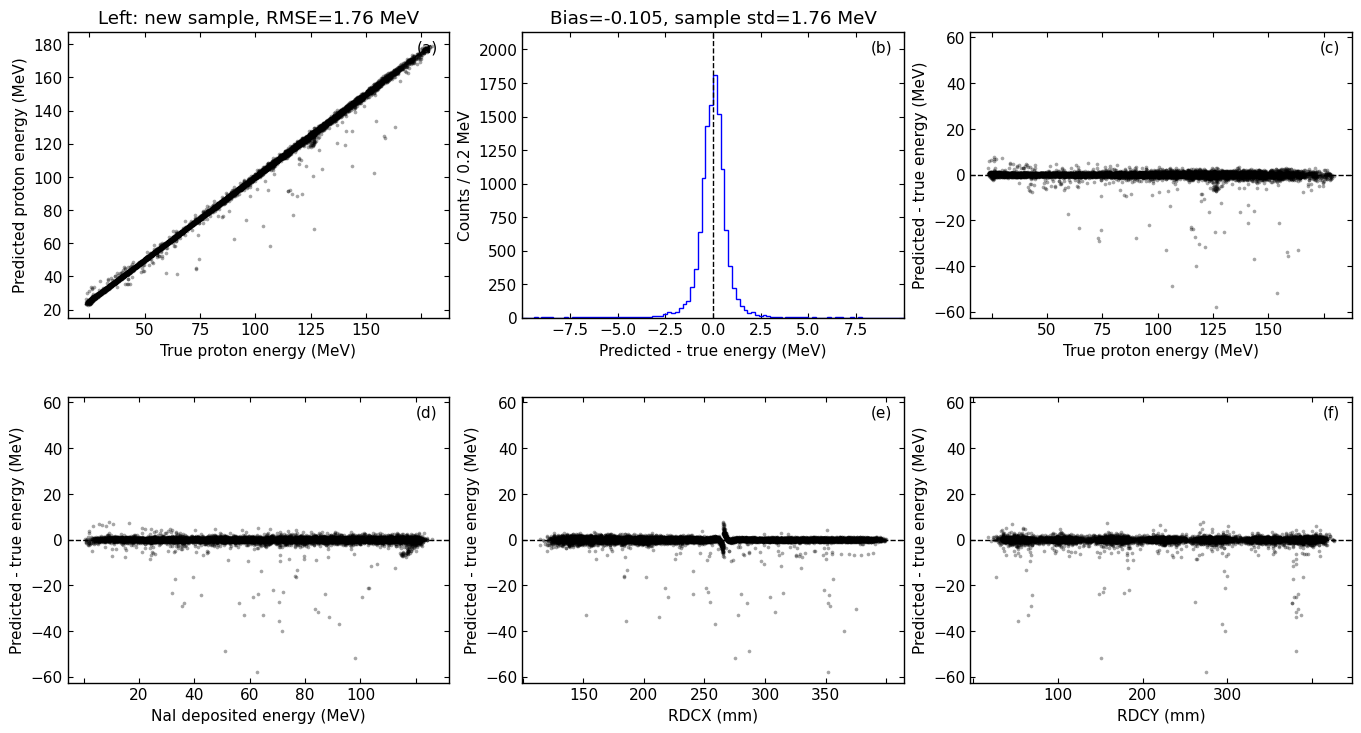

Right {
  "n": 11792,
  "mse_MeV2": 3.608447425285513,
  "rmse_MeV": 1.8995913837679705,
  "mae_MeV": 0.6297843451849426,
  "r2": 0.9972972727880783,
  "bias_MeV": -0.13274711602876763,
  "residual_std_MeV": 1.8950277486105904,
  "residual_q16_MeV": -0.5961219305664048,
  "residual_median_MeV": -0.008332702365819955,
  "residual_q84_MeV": 0.5525374026704247,
  "central68_half_width_MeV": 0.5743296666184148
}
Right new sample: residual histogram below range=42, above range=0; metrics use all 11792 events


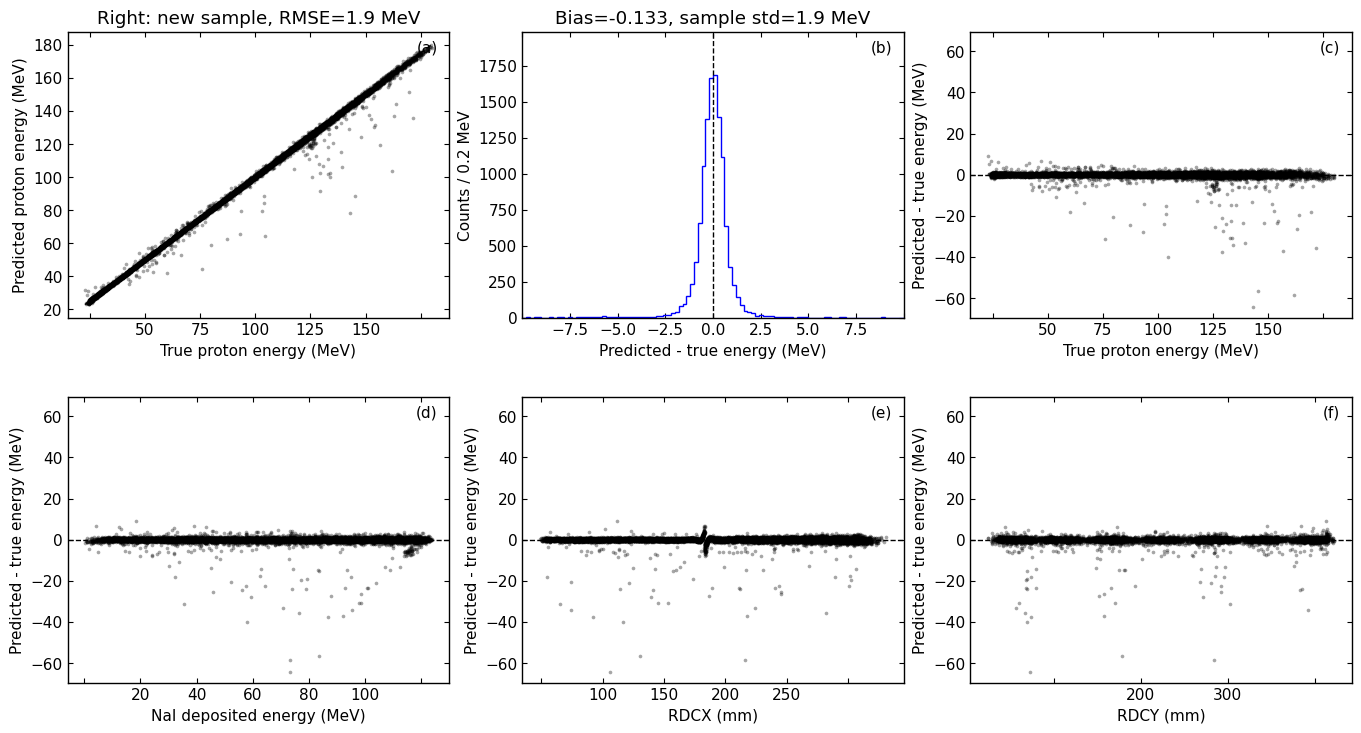

In [7]:
if not results:
    print("尚无预测结果；新 ROOT 文件生成后填写配置并从头运行。")
for arm, result in results.items():
    if result["metrics"] is None:
        print(f"{arm}: 没有可用 ETrue，已保存预测，跳过误差指标。")
        continue
    print(arm, json.dumps(result["metrics"], ensure_ascii=False, indent=2))
    mask = result["truth_ok"]
    plot_diagnostics(arm, result["X"][mask], result["truth"][mask, 0], result["prediction"][mask],
                     EVALUATION_OUTPUT_DIR / f"EvaluationDiagnostics_{arm}.pdf", "new sample")
